In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.tree import DecisionTreeRegressor

plt.rcParams["figure.dpi"] = 110
SEED = 42
ROOT = Path(".") if Path("data").exists() else Path("..")
OUT_DIR = ROOT / "data/processed"

fires_daily = pd.read_csv(OUT_DIR / "fires_daily.csv", parse_dates=["date"]).set_index("date")

In [2]:
merged_path = OUT_DIR / "topicA_daily.csv"
if merged_path.exists():
    target = pd.read_csv(merged_path, parse_dates=["date"]).set_index("date")["pm25"]
else:
    pm = pd.read_csv(ROOT / "data/raw/air_quality/pm25_hourly_mar_nov.csv")
    pm["time"] = pd.to_datetime(pm["datetime_from_local"].str[:19])
    target = pm.set_index("time")["value"].resample("D").mean()
print("PM2.5 source:", "topicA_daily.csv" if merged_path.exists() else "raw hourly file (temporary)")

PM2.5 source: raw hourly file (temporary)


In [3]:
model_df = fires_daily.drop(columns="fire_level").join(target.rename("pm25"))
for col in ["fire_count", "fire_frp", "fire_frp_distw", "fire_near300"]:
    model_df[f"{col}_lag1"] = model_df[col].shift(1)

FEATURES_B = ["fire_count", "fire_frp", "fire_frp_distw", "fire_near300", "fire_nw", "fire_south", "fire_night",
              "fire_count_lag1", "fire_frp_lag1", "fire_frp_distw_lag1", "fire_near300_lag1",
              "fire_count_prev3", "fire_count_prev7", "is_burning_season"]
model_df = model_df.dropna(subset=FEATURES_B + ["pm25"])
X, y = model_df[FEATURES_B], model_df["pm25"]
X.shape

(270, 14)

In [4]:
tscv = TimeSeriesSplit(n_splits=5)

def walk_forward(model, X, y):
    fold_mae = []
    oof = pd.Series(np.nan, index=y.index)
    for train, test in tscv.split(X):
        if model is None:
            pred = np.full(len(test), y.iloc[train].mean())
        else:
            model.fit(X.iloc[train], np.log1p(y.iloc[train]))
            pred = np.expm1(model.predict(X.iloc[test]))
        oof.iloc[test] = pred
        fold_mae.append(mean_absolute_error(y.iloc[test], pred))
    done = oof.notna()
    scores = {"MAE": np.mean(fold_mae), "MAE std": np.std(fold_mae),
              "RMSE": mean_squared_error(y[done], oof[done]) ** 0.5,
              "R2": r2_score(y[done], oof[done])}
    return scores, oof

In [5]:
tuned_tree = GridSearchCV(
    DecisionTreeRegressor(random_state=SEED),
    {"max_depth": [2, 3, 4, 6, None], "min_samples_leaf": [1, 5, 10]},
    cv=TimeSeriesSplit(n_splits=3), scoring="neg_mean_absolute_error")

models_B = {
    "Mean baseline": None,
    "Linear Regression": LinearRegression(),
    "Decision Tree (tuned)": tuned_tree,
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
}
results, oof_preds = {}, {}
for name, model in models_B.items():
    results[name], oof_preds[name] = walk_forward(model, X, y)

results_B = pd.DataFrame(results).T.round(2)
results_B["MAE gain vs baseline (%)"] = (100 * (1 - results_B["MAE"] / results_B.loc["Mean baseline", "MAE"])).round(1)
results_B

,MAE,MAE std,RMSE,R2,MAE gain vs baseline (%)
Mean baseline,38.51,34.92,60.81,-0.15,0.0
Linear Regression,40.97,33.96,68.55,-0.46,-6.4
Decision Tree (tuned),27.59,32.96,52.92,0.13,28.4
Random Forest,26.14,32.94,51.79,0.16,32.1


In [6]:
fold_rows = []
for i, (train, test) in enumerate(tscv.split(X), start=1):
    days = y.index[test]
    fold_rows.append({"fold": i, "test period": f"{days.min():%d %b} to {days.max():%d %b}",
                      **{n: round(mean_absolute_error(y.loc[days], oof_preds[n].loc[days]), 1) for n in models_B}})
pd.DataFrame(fold_rows).set_index("fold")

,test period,Mean baseline,Linear Regression,Decision Tree (tuned),Random Forest
fold,,,,,
1,17 Apr to 01 Jun,16.9,73.2,15.2,16.1
2,04 Jun to 18 Jul,24.0,14.2,11.6,7.6
3,19 Jul to 01 Sep,29.1,14.5,7.0,5.9
4,02 Sep to 16 Oct,15.0,12.2,10.9,9.4
5,17 Oct to 30 Nov,107.6,90.8,93.3,91.6


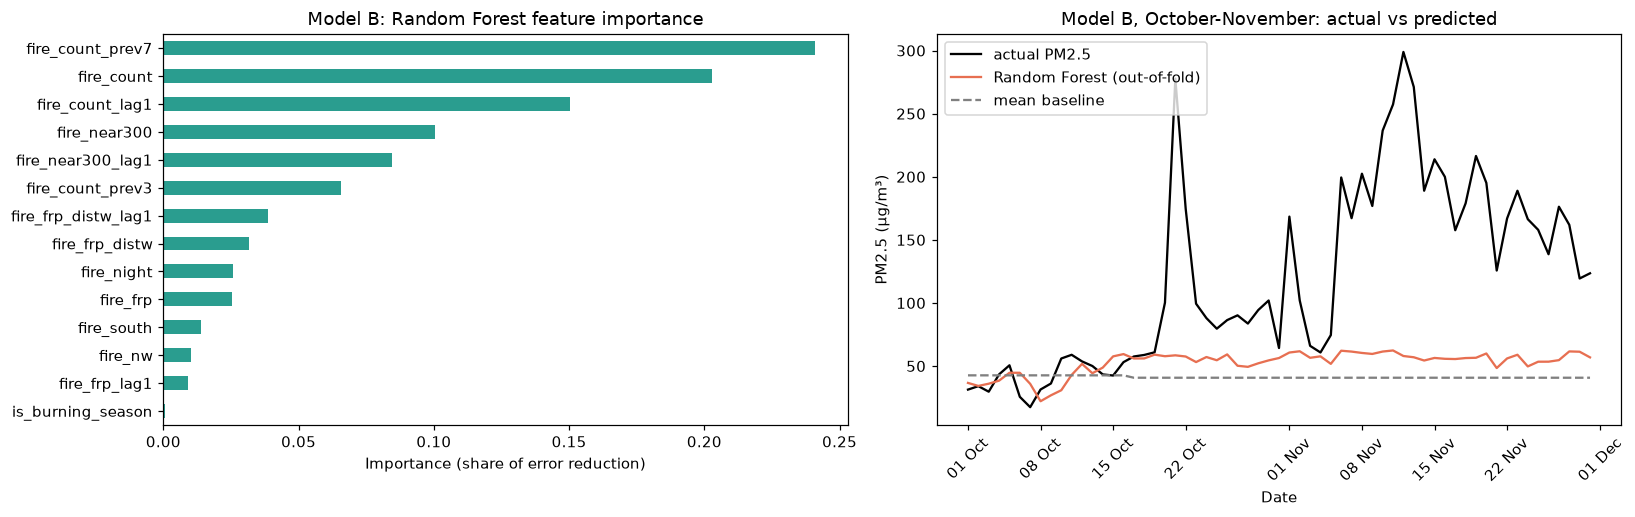

In [8]:
rf = models_B["Random Forest"].fit(X, np.log1p(y))
importance = pd.Series(rf.feature_importances_, index=FEATURES_B).sort_values()
on = y.index.month >= 10

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
importance.plot(kind="barh", ax=axes[0], color="#2a9d8f")
axes[0].set_title("Model B: Random Forest feature importance")
axes[0].set_xlabel("Importance (share of error reduction)")

axes[1].plot(y[on], color="k", label="actual PM2.5")
axes[1].plot(oof_preds["Random Forest"][on], color="#e76f51", label="Random Forest (out-of-fold)")
axes[1].plot(oof_preds["Mean baseline"][on], color="grey", ls="--", label="mean baseline")
axes[1].set_title("Model B, October-November: actual vs predicted")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("PM2.5 (µg/m³)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
fig.tight_layout()
plt.show()